# Machine Learning Capstone Project

## Water Treatment Plant Clustering

### Review 2 - Clustering Track

**Problem Statement:**  
Wastewater treatment plants collect measurements at different stages of the treatment process. Identifying patterns in these measurements can help reveal groups of similar operating conditions.

**Objective:**  
Apply unsupervised machine learning algorithms to the Water Treatment Plant dataset to identify clusters of similar observations, evaluate clustering performance, and visualise the resulting clusters.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

# 1. Dataset Loading

The Water Treatment Plant dataset contains measurements from different stages of a wastewater treatment process. The raw data file does not include column headers, so the attribute names are assigned explicitly when loading the data.

In [3]:
columns = [
    "Date",
    "Q-E", "ZN-E", "PH-E", "DBO-E", "DQO-E",
    "SS-E", "SSV-E", "SED-E", "COND-E",
    "PH-P", "DBO-P", "SS-P", "SSV-P", "SED-P", "COND-P",
    "PH-D", "DBO-D", "DQO-D", "SS-D", "SSV-D", "SED-D", "COND-D",
    "PH-S", "DBO-S", "DQO-S", "SS-S", "SSV-S", "SED-S", "COND-S",
    "RD-DBO-P", "RD-SS-P", "RD-SED-P",
    "RD-DBO-S", "RD-DQO-S",
    "RD-DBO-G", "RD-DQO-G", "RD-SS-G", "RD-SED-G"
]

df = pd.read_csv(
    "water-treatment.data",
    header=None,
    names=columns,
    na_values="?",
    skipinitialspace=True
)

df.head()

,Date,Q-E,ZN-E,PH-E,DBO-E,DQO-E,SS-E,SSV-E,SED-E,COND-E,...,COND-S,RD-DBO-P,RD-SS-P,RD-SED-P,RD-DBO-S,RD-DQO-S,RD-DBO-G,RD-DQO-G,RD-SS-G,RD-SED-G
0,D-1/3/90,44101.0,1.5,7.8,NaN,407.0,166.0,66.3,4.5,2110,...,2000.0,NaN,58.8,95.5,NaN,70.0,NaN,79.4,87.3,99.6
1,D-2/3/90,39024.0,3.0,7.7,NaN,443.0,214.0,69.2,6.5,2660,...,2590.0,NaN,60.7,94.8,NaN,80.8,NaN,79.5,92.1,100.0
2,D-4/3/90,32229.0,5.0,7.6,NaN,528.0,186.0,69.9,3.4,1666,...,1888.0,NaN,58.2,95.6,NaN,52.9,NaN,75.8,88.7,98.5
3,D-5/3/90,35023.0,3.5,7.9,205.0,588.0,192.0,65.6,4.5,2430,...,1840.0,33.1,64.2,95.3,87.3,72.3,90.2,82.3,89.6,100.0
4,D-6/3/90,36924.0,1.5,8.0,242.0,496.0,176.0,64.8,4.0,2110,...,2120.0,NaN,62.7,95.6,NaN,71.0,92.1,78.2,87.5,99.5


In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (527, 39)

Column Names:
['Date', 'Q-E', 'ZN-E', 'PH-E', 'DBO-E', 'DQO-E', 'SS-E', 'SSV-E', 'SED-E', 'COND-E', 'PH-P', 'DBO-P', 'SS-P', 'SSV-P', 'SED-P', 'COND-P', 'PH-D', 'DBO-D', 'DQO-D', 'SS-D', 'SSV-D', 'SED-D', 'COND-D', 'PH-S', 'DBO-S', 'DQO-S', 'SS-S', 'SSV-S', 'SED-S', 'COND-S', 'RD-DBO-P', 'RD-SS-P', 'RD-SED-P', 'RD-DBO-S', 'RD-DQO-S', 'RD-DBO-G', 'RD-DQO-G', 'RD-SS-G', 'RD-SED-G']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 527 entries, 0 to 526
Data columns (total 39 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Date      527 non-null    str    
 1   Q-E       509 non-null    float64
 2   ZN-E      524 non-null    float64
 3   PH-E      527 non-null    float64
 4   DBO-E     504 non-null    float64
 5   DQO-E     521 non-null    float64
 6   SS-E      526 non-null    float64
 7   SSV-E     516 non-null    float64
 8   SED-E     502 non-null    float64
 9   COND-E    527 non-null    int64  
 10  PH

# 2. Missing Values and Duplicate Records

Missing values and duplicate records are checked to assess the quality of the dataset. These checks help determine whether data cleaning is required before clustering.

In [5]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing_values[missing_values["Missing Count"] > 0]

,Missing Count,Missing Percentage
Q-E,18,3.42
ZN-E,3,0.57
DBO-E,23,4.36
DQO-E,6,1.14
SS-E,1,0.19
SSV-E,11,2.09
SED-E,25,4.74
DBO-P,40,7.59
SSV-P,11,2.09
SED-P,24,4.55


In [6]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


# 3. Descriptive Statistics

Descriptive statistics are calculated to understand the distribution and variability of the dataset attributes. Measures such as mean, standard deviation, minimum, and maximum help identify differences in measurement scales and possible unusual values.

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Q-E,509.0,37226.567780,6635.999806,10050.0,32888.000,35990.00,41372.000,60081.0
ZN-E,524.0,2.359065,2.749509,0.1,0.900,1.50,3.000,33.5
PH-E,527.0,7.810057,0.246175,6.9,7.600,7.80,8.000,8.7
DBO-E,504.0,188.714286,62.062831,31.0,146.750,182.50,223.000,438.0
DQO-E,521.0,406.898273,120.362974,81.0,325.000,400.00,478.000,941.0
SS-E,526.0,227.444867,135.940589,98.0,170.000,196.00,242.000,2008.0
SSV-E,516.0,61.393217,12.415264,13.2,55.700,64.30,69.725,85.0
SED-E,502.0,4.593825,2.743947,0.4,3.100,4.50,5.500,36.0
COND-E,527.0,1478.620493,394.898019,651.0,1201.000,1406.00,1672.000,3230.0
PH-P,527.0,7.829981,0.226925,7.3,7.700,7.80,8.000,8.5


# 4. Data Cleaning and Feature Engineering

Remove unnecessary variables and prepare the numerical features for clustering.

In [8]:
# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Remove the date column and keep numerical features
X = df.drop(columns=["Date"]).copy()

# Convert values to numeric
X = X.apply(pd.to_numeric, errors="coerce")

# Remove columns containing only missing values
X = X.dropna(axis=1, how="all")

print("Feature shape before imputation:", X.shape)
print("Missing values before imputation:", X.isnull().sum().sum())

Feature shape before imputation: (527, 38)
Missing values before imputation: 591


## Handle Missing Values

Replace missing numerical values with the median of each feature.

In [9]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns,
    index=X.index
)

print("Missing values after imputation:", X.isnull().sum().sum())

Missing values after imputation: 0


## Feature Engineering

Remove constant features that do not contribute information to clustering.

In [10]:
constant_features = X.columns[X.nunique() <= 1].tolist()

X = X.drop(columns=constant_features)

print("Constant features removed:", constant_features)
print("Final feature shape:", X.shape)

X.head()

Constant features removed: []
Final feature shape: (527, 38)


,Q-E,ZN-E,PH-E,DBO-E,DQO-E,SS-E,SSV-E,SED-E,COND-E,PH-P,...,COND-S,RD-DBO-P,RD-SS-P,RD-SED-P,RD-DBO-S,RD-DQO-S,RD-DBO-G,RD-DQO-G,RD-SS-G,RD-SED-G
0,44101.0,1.5,7.8,182.5,407.0,166.0,66.3,4.5,2110.0,7.9,...,2000.0,39.6,58.8,95.5,85.4,70.0,90.2,79.4,87.3,99.6
1,39024.0,3.0,7.7,182.5,443.0,214.0,69.2,6.5,2660.0,7.7,...,2590.0,39.6,60.7,94.8,85.4,80.8,90.2,79.5,92.1,100.0
2,32229.0,5.0,7.6,182.5,528.0,186.0,69.9,3.4,1666.0,7.7,...,1888.0,39.6,58.2,95.6,85.4,52.9,90.2,75.8,88.7,98.5
3,35023.0,3.5,7.9,205.0,588.0,192.0,65.6,4.5,2430.0,7.8,...,1840.0,33.1,64.2,95.3,87.3,72.3,90.2,82.3,89.6,100.0
4,36924.0,1.5,8.0,242.0,496.0,176.0,64.8,4.0,2110.0,7.9,...,2120.0,39.6,62.7,95.6,85.4,71.0,92.1,78.2,87.5,99.5


# 5. Exploratory Data Analysis (EDA)

Visualise the distributions and correlations of the numerical features.

## Feature Distributions

Visualize the distribution of each numerical feature.

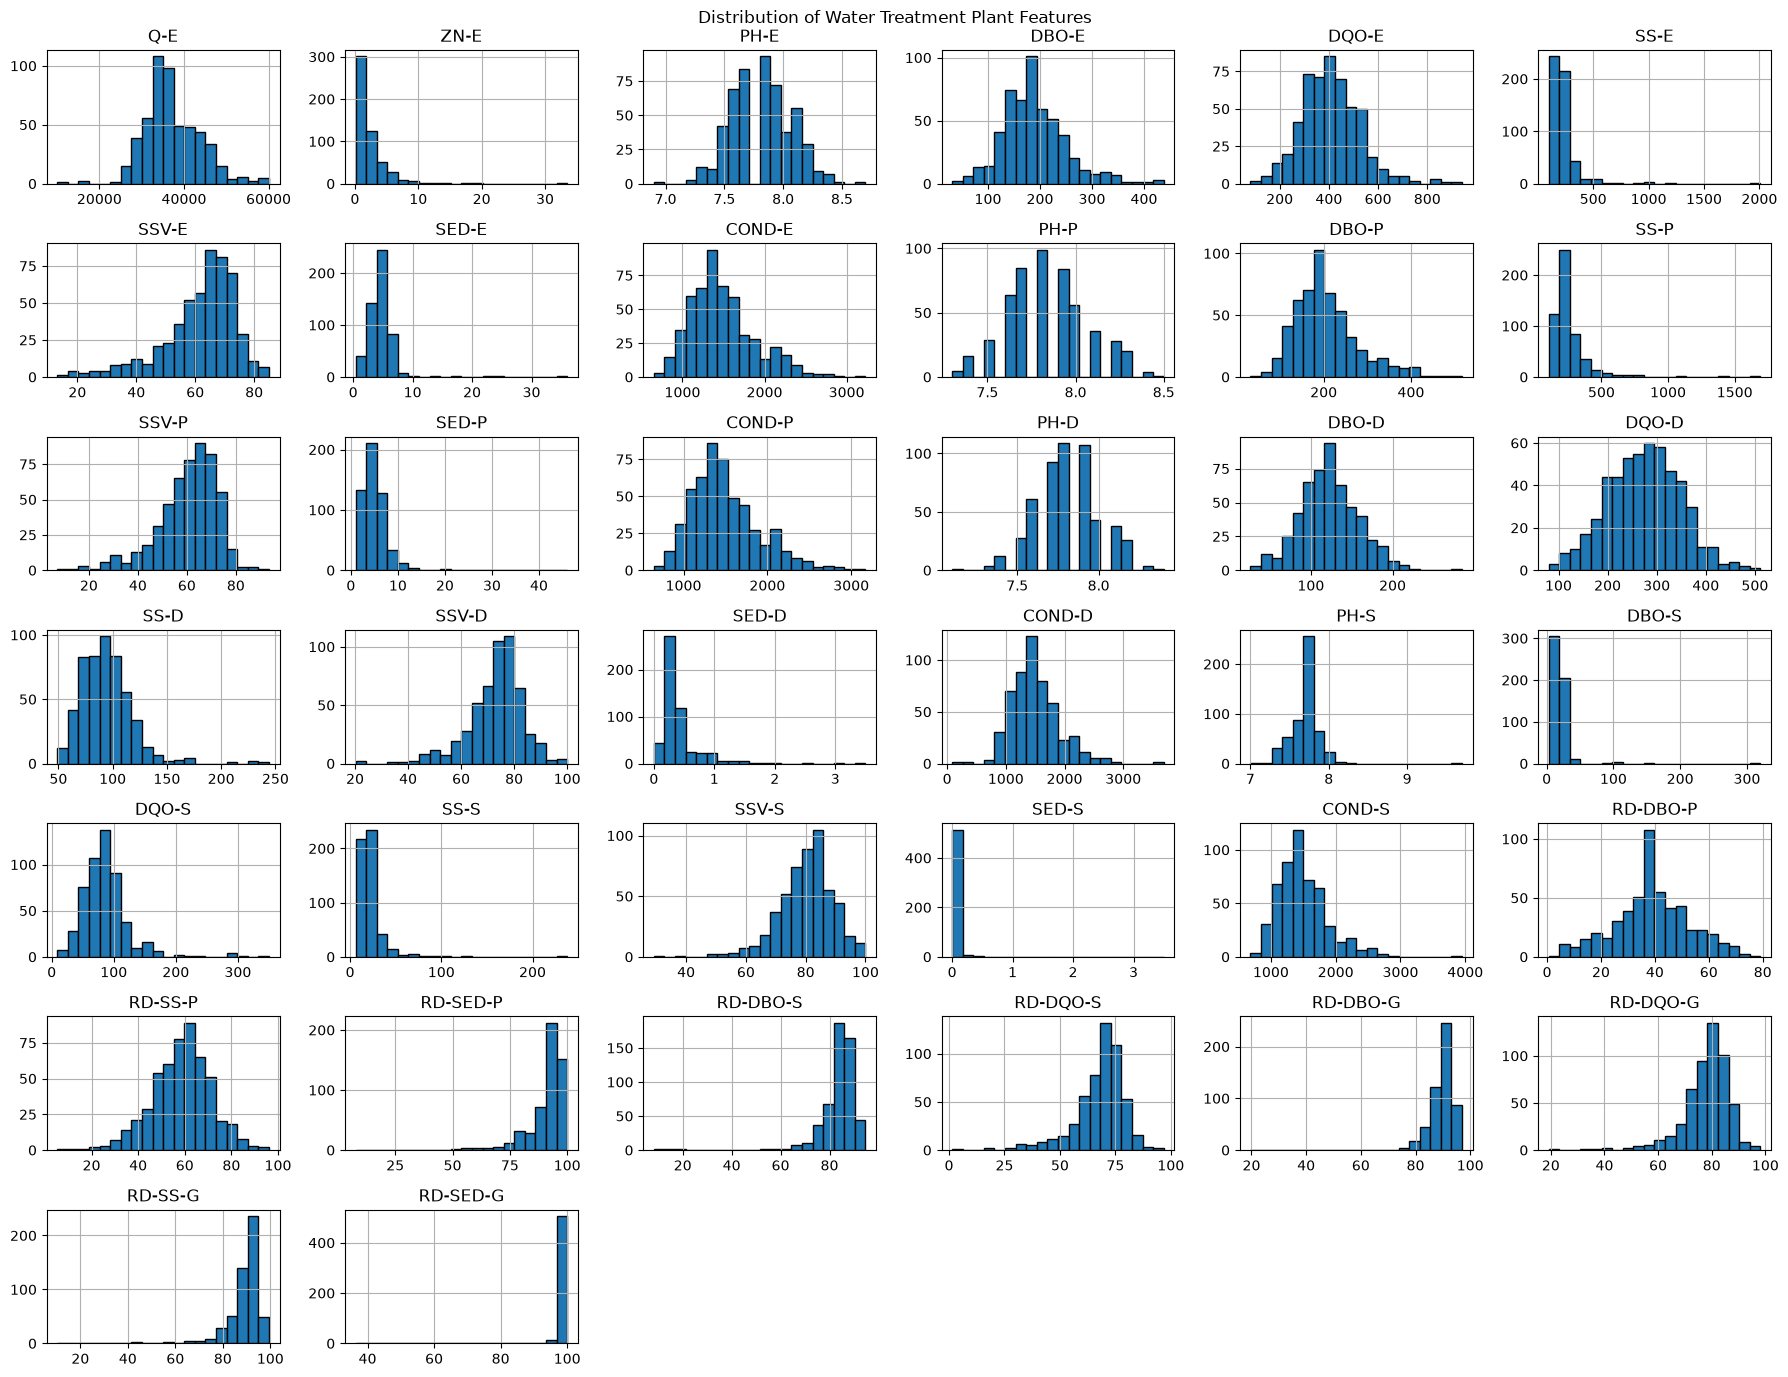

In [11]:
X.hist(figsize=(18, 14), bins=20, edgecolor="black")

plt.suptitle("Distribution of Water Treatment Plant Features")
plt.tight_layout()
plt.show()

### Observation

The plots show the distributions and ranges of the water-treatment measurements.

## Correlation Heatmap

Examine the correlations between numerical features.

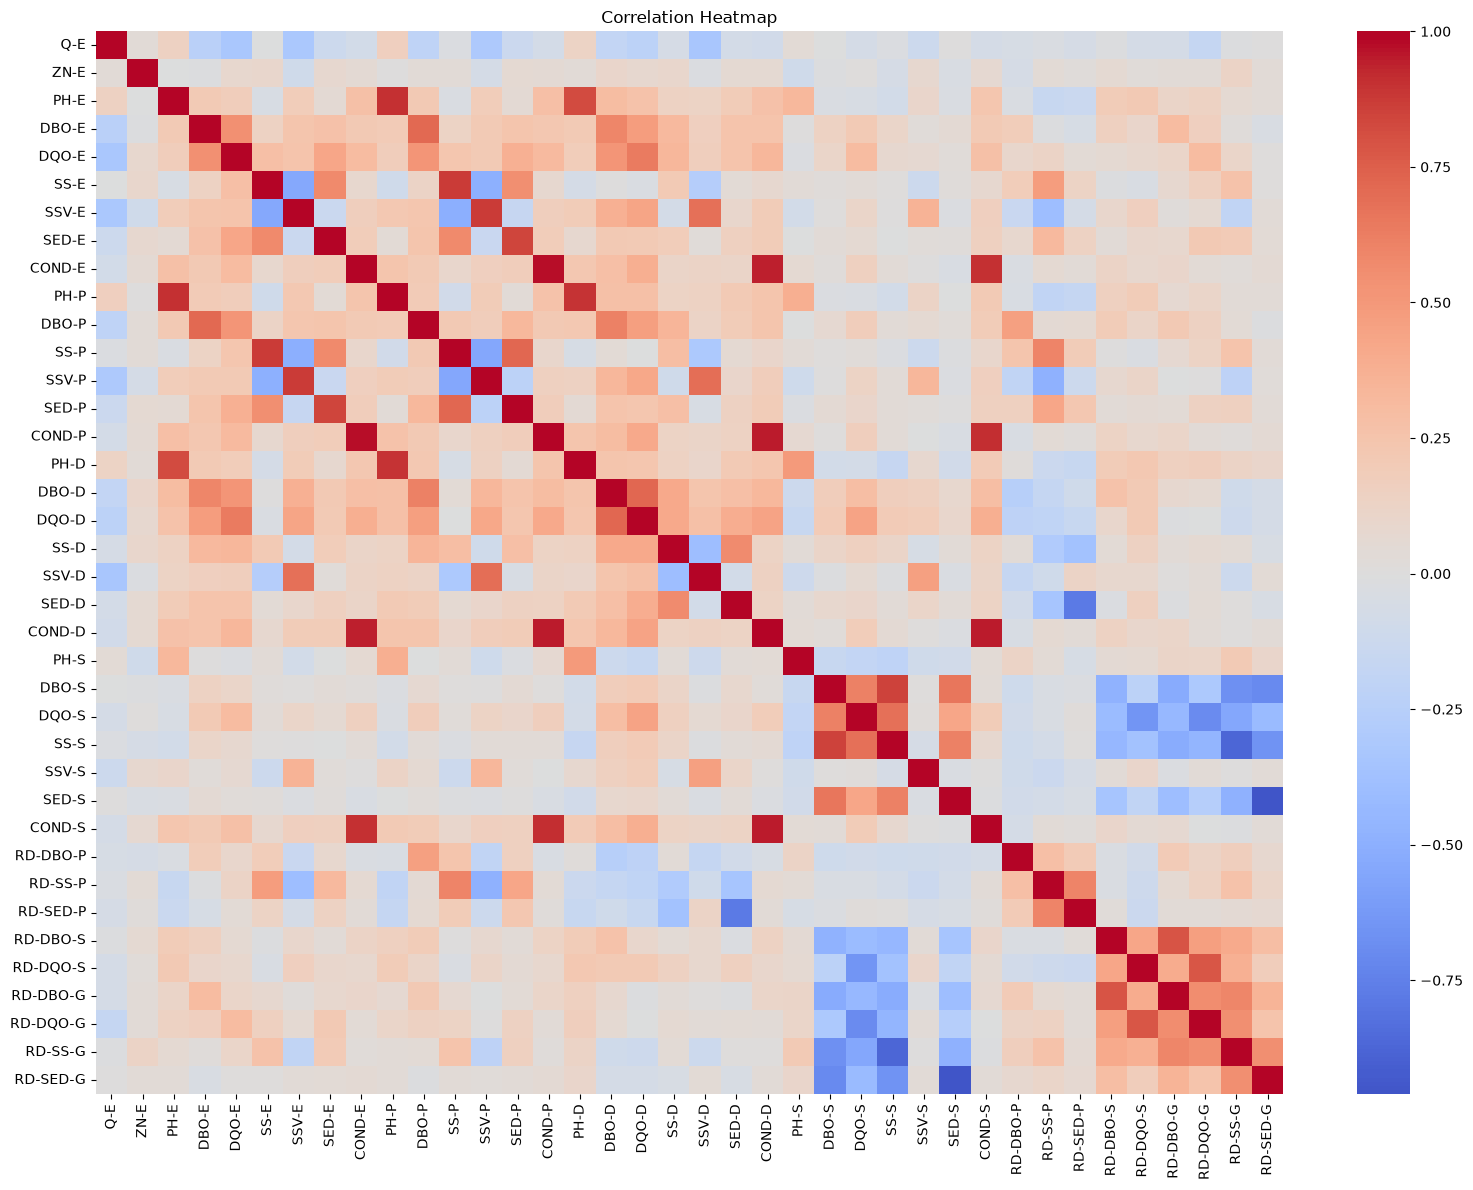

In [12]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    X.corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

### Observation

The heatmap shows the strength and direction of relationships between the numerical features.

## Feature Scatter Plots

Examine the relationships between selected water-treatment measurements.

### pH vs Conductivity at the Entry Stage

This scatter plot examines the relationship between pH and conductivity in the incoming wastewater.

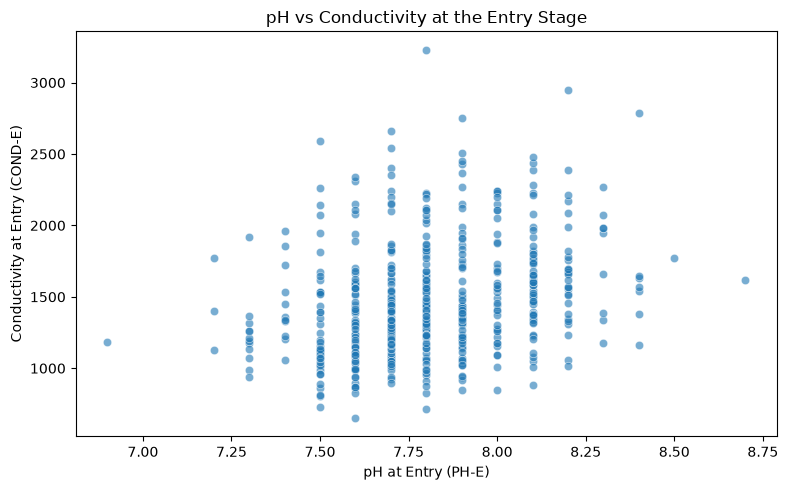

In [13]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=X,
    x="PH-E",
    y="COND-E",
    alpha=0.6
)

plt.title("pH vs Conductivity at the Entry Stage")
plt.xlabel("pH at Entry (PH-E)")
plt.ylabel("Conductivity at Entry (COND-E)")
plt.tight_layout()
plt.show()

### Incoming vs Outgoing BOD

This scatter plot compares the biological oxygen demand (BOD) of incoming wastewater with the BOD measured at the final treatment stage.

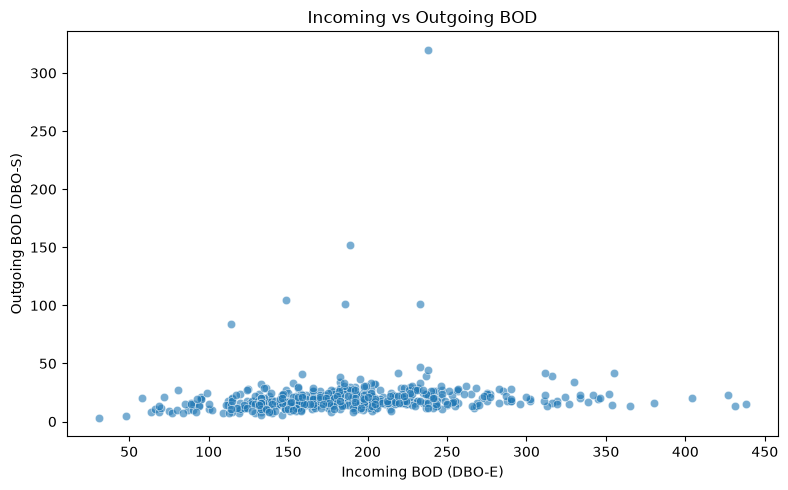

In [14]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=X,
    x="DBO-E",
    y="DBO-S",
    alpha=0.6
)

plt.title("Incoming vs Outgoing BOD")
plt.xlabel("Incoming BOD (DBO-E)")
plt.ylabel("Outgoing BOD (DBO-S)")
plt.tight_layout()
plt.show()

### Observation

The scatter plots show how selected water-treatment measurements vary together across observations.

# 6. Outlier Detection and Treatment

Outliers are inspected using boxplots and the IQR rule. K-Means and
hierarchical clustering are distance-based, so extreme values can pull
cluster centres towards them. Observations are not deleted because the
dataset is small (527 rows). Values are instead **capped** at the IQR
boundaries (winsorisation).

,Feature,Potential Outliers
31,RD-SED-P,44
20,SED-D,41
37,RD-SED-G,41
11,SS-P,39
5,SS-E,39
36,RD-SS-G,39
25,SS-S,34
1,ZN-E,33
27,SED-S,30
33,RD-DQO-S,28


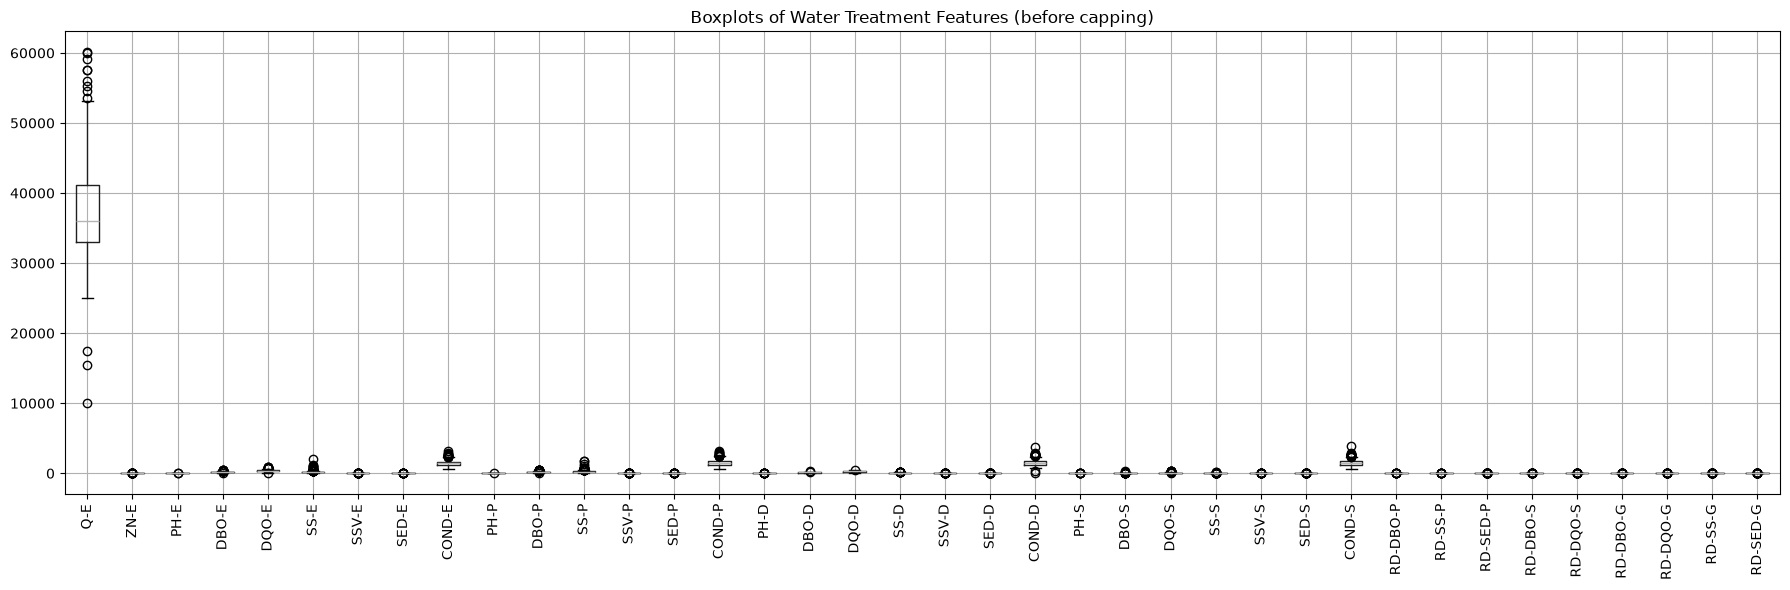

In [15]:
outlier_counts = {}
for col in X.columns:
    Q1, Q3 = X[col].quantile(0.25), X[col].quantile(0.75)
    IQR = Q3 - Q1
    outlier_counts[col] = int(((X[col] < Q1 - 1.5 * IQR) | (X[col] > Q3 + 1.5 * IQR)).sum())

outlier_table = (pd.DataFrame({"Feature": list(outlier_counts.keys()),
                               "Potential Outliers": list(outlier_counts.values())})
                 .sort_values("Potential Outliers", ascending=False))
display(outlier_table.head(15))

plt.figure(figsize=(18, 6))
X.boxplot(rot=90)
plt.title("Boxplots of Water Treatment Features (before capping)")
plt.tight_layout()
plt.show()

In [16]:
X_capped = X.copy()
for col in X_capped.columns:
    Q1, Q3 = X_capped[col].quantile(0.25), X_capped[col].quantile(0.75)
    IQR = Q3 - Q1
    X_capped[col] = X_capped[col].clip(Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)

print("Outlier capping completed. Shape:", X_capped.shape)

Outlier capping completed. Shape: (527, 38)


### Observation – Outliers

Several features (e.g. flow `Q-E`, solids `SS-E`, `SED-E` and conductivity columns) contain many points beyond the IQR fences. These may be real
unusual operating days (storms, plant faults) rather than errors, so they are capped instead of removed to keep every observation.

# 7. Feature Engineering

Two features are created from the incoming (entry-stage) measurements:

- `DQO_DBO_ratio_E` = COD / BOD at the entry stage. This is a standard
  biodegradability index. A high ratio means more non-biodegradable
  pollution, so it may separate different operating conditions.
- `VolatileFraction_E` = SSV-E / SS-E, the share of suspended solids that
  is organic. This describes the *type* of load, not only its amount, which
  may help clustering.

`+1` is added to the denominators to avoid division by zero.

In [17]:
X_fe = X_capped.copy()
X_fe["DQO_DBO_ratio_E"] = X_fe["DQO-E"] / (X_fe["DBO-E"] + 1)
X_fe["VolatileFraction_E"] = X_fe["SSV-E"] / (X_fe["SS-E"] + 1)

print("Final feature shape:", X_fe.shape)
display(X_fe[["DQO-E", "DBO-E", "DQO_DBO_ratio_E", "SSV-E", "SS-E", "VolatileFraction_E"]].head())

Final feature shape: (527, 40)


,DQO-E,DBO-E,DQO_DBO_ratio_E,SSV-E,SS-E,VolatileFraction_E
0,407.0,182.5,2.217984,66.3,166.0,0.397006
1,443.0,182.5,2.414169,69.2,214.0,0.321860
2,528.0,182.5,2.877384,69.9,186.0,0.373797
3,588.0,205.0,2.854369,65.6,192.0,0.339896
4,496.0,242.0,2.041152,64.8,176.0,0.366102


# 8. Feature Scaling

The features are on very different scales (flow `Q-E` is in the tens of
thousands, pH is about 7-8). Distance-based clustering would be dominated
by large-scale features, so all features are standardised with
`StandardScaler` (mean 0, standard deviation 1). No train/test split is
needed because clustering is unsupervised.

In [18]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_fe)
X_scaled_df = pd.DataFrame(X_scaled, columns=X_fe.columns)

print("Scaled shape:", X_scaled.shape)
print("Mean of first features:", X_scaled_df.mean().round(3).head().tolist())
print("Std of first features :", X_scaled_df.std().round(3).head().tolist())

Scaled shape: (527, 40)
Mean of first features: [-0.0, 0.0, 0.0, 0.0, 0.0]
Std of first features : [1.001, 1.001, 1.001, 1.001, 1.001]


# 9. PCA – Variance Explained

PCA shows how many components are needed to keep most of the information.
It is also used later to draw the clusters in 2D.

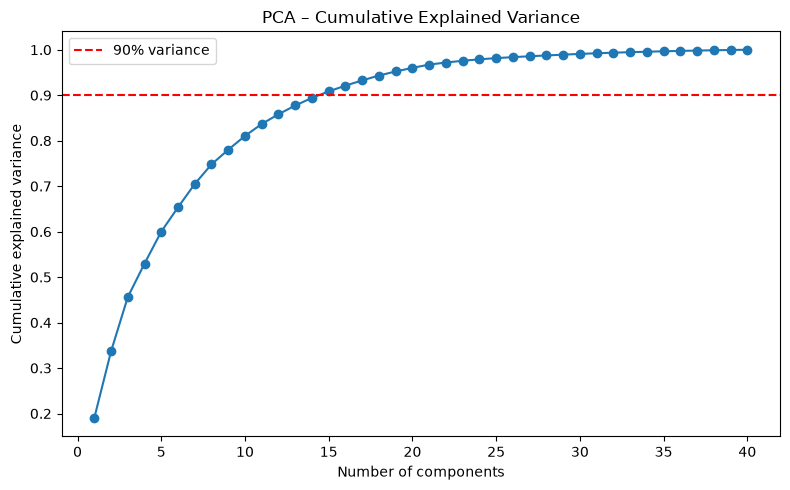

15 components explain 90% of the variance.


In [19]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_90 = int(np.argmax(cum_var >= 0.90) + 1)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker="o")
plt.axhline(0.90, color="red", linestyle="--", label="90% variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA – Cumulative Explained Variance")
plt.legend()
plt.tight_layout()
plt.show()

print(f"{n_90} components explain 90% of the variance.")

# 10. K-Means Clustering

The number of clusters *k* is chosen using the elbow method (inertia) and
the silhouette score for k = 2 to 10.

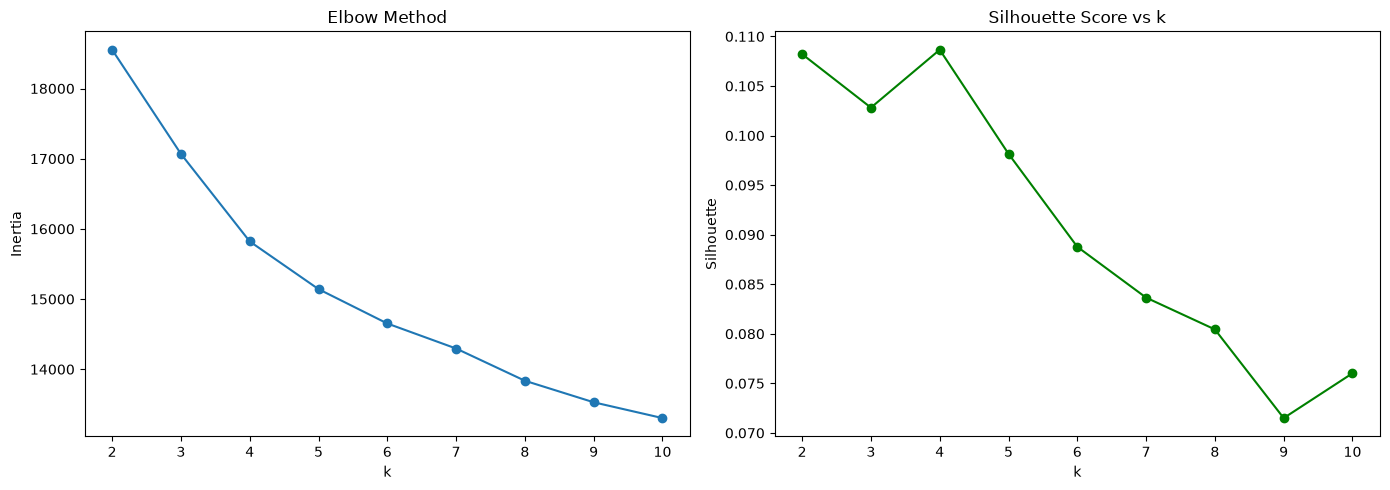

,k,Inertia,Silhouette
0,2,18552.1249,0.1082
1,3,17068.7126,0.1028
2,4,15821.2121,0.1087
3,5,15141.6091,0.0982
4,6,14652.0169,0.0888
5,7,14295.5379,0.0836
6,8,13836.2484,0.0804
7,9,13529.4119,0.0715
8,10,13304.3997,0.0760


Best k by silhouette: 4


In [20]:
k_range = range(2, 11)
inertias, sil_scores = [], []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(list(k_range), inertias, marker="o")
ax[0].set_title("Elbow Method"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia")
ax[1].plot(list(k_range), sil_scores, marker="o", color="green")
ax[1].set_title("Silhouette Score vs k"); ax[1].set_xlabel("k"); ax[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

display(pd.DataFrame({"k": list(k_range), "Inertia": inertias, "Silhouette": sil_scores}).round(4))

best_k = list(k_range)[int(np.argmax(sil_scores))]
print("Best k by silhouette:", best_k)

In [21]:
# If the elbow and silhouette disagree, you may override best_k here
# e.g. best_k = 3   (justify your choice in the markdown cell below)

kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("Cluster sizes (K-Means):")
print(pd.Series(kmeans_labels).value_counts().sort_index())

Cluster sizes (K-Means):
0    120
1    165
2     86
3    156
Name: count, dtype: int64


### Observation – Choice of k
The elbow curve bends at about k = [..], and the silhouette score is
highest at k = [..]. **[Fill in from your plots.]** This k is used for all
algorithms below so they can be compared fairly.